# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Question 1

## RGB

(-0.5, 617.5, 359.5, -0.5)

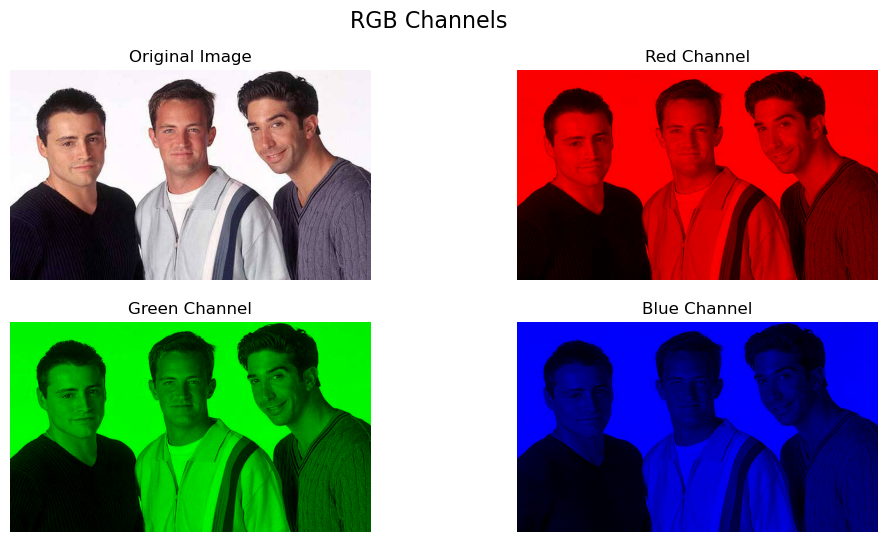

In [2]:
image = cv2.imread('./img_and_vids/1.jpg', cv2.IMREAD_COLOR)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
r, g, b = cv2.split(image_rgb)

zeros = np.zeros_like(b)

red_channel = np.stack([r, zeros, zeros], axis=2)
green_channel = np.stack([zeros, g, zeros], axis=2)
blue_channel = np.stack([zeros, zeros, b], axis=2)

plt.figure(figsize=(12,6))
plt.suptitle('RGB Channels', size=16)

plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(image_rgb)
plt.axis('off')

plt.subplot(2,2,2)
plt.title('Red Channel')
plt.imshow(red_channel)
plt.axis('off')

plt.subplot(2,2,3)
plt.title('Green Channel')
plt.imshow(green_channel)
plt.axis('off')

plt.subplot(2,2,4)
plt.title('Blue Channel')
plt.imshow(blue_channel)
plt.axis('off')

(-0.5, 617.5, 359.5, -0.5)

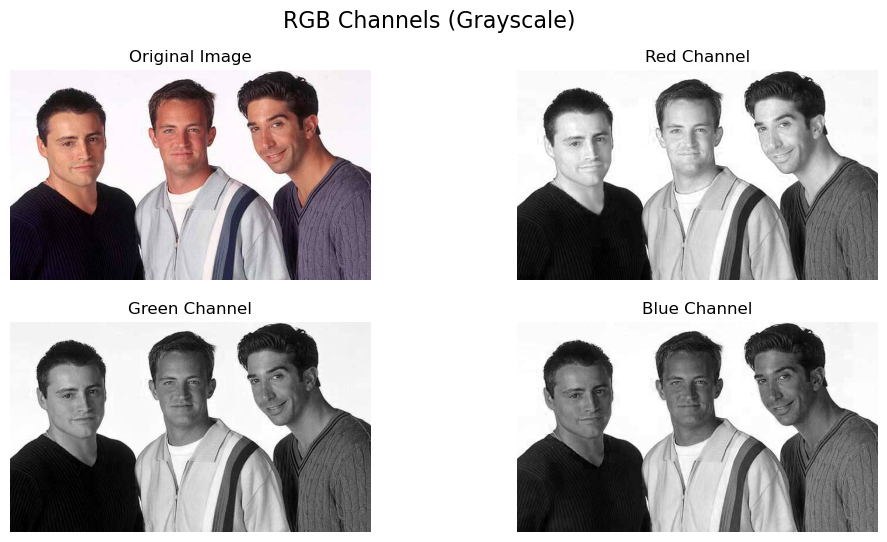

In [3]:
plt.figure(figsize=(12,6))
plt.suptitle('RGB Channels (Grayscale)', size=16)

plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(image_rgb)
plt.axis('off')

plt.subplot(2,2,2)
plt.title('Red Channel')
plt.imshow(r, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title('Green Channel')
plt.imshow(g, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title('Blue Channel')
plt.imshow(b, cmap='gray')
plt.axis('off')

## HSV

(-0.5, 617.5, 359.5, -0.5)

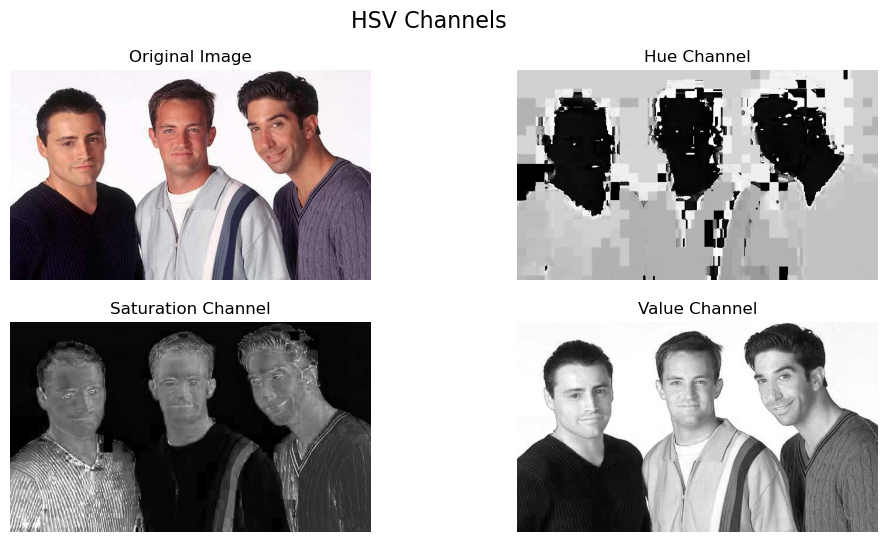

In [4]:
def rgb_to_hsv(rgb_img):
    img = rgb_img.astype(float) / 255.0 #normalize
    r, g, b = img[:,:,0], img[:,:,1], img[:,:,2] #cv2.split
    
    max_c = np.max(img, axis=2)
    min_c = np.min(img, axis=2)
    delta = max_c - min_c

    h = np.zeros_like(max_c)
    
    mask_r = (max_c == r) & (delta != 0)
    h[mask_r] = (60 * ((g[mask_r] - b[mask_r]) / delta[mask_r]) % 360)
    
    mask_g = (max_c == g) & (delta != 0)
    h[mask_g] = (60 * ((b[mask_g] - r[mask_g]) / delta[mask_g]) + 120)
    
    mask_b = (max_c == b) & (delta != 0)
    h[mask_b] = (60 * ((r[mask_b] - g[mask_b]) / delta[mask_b]) + 240)
    
    s = np.zeros_like(max_c)
    s[max_c != 0] = delta[max_c != 0] / max_c[max_c != 0]
    
    v = max_c
    
    return h/360.0, s, v

h, s, v = rgb_to_hsv(image_rgb)

plt.figure(figsize=(12,6))
plt.suptitle('HSV Channels', size=16)

plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(image_rgb)
plt.axis('off')

plt.subplot(2,2,2)
plt.title('Hue Channel')
plt.imshow(h, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title('Saturation Channel')
plt.imshow(s, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title('Value Channel')
plt.imshow(v, cmap='gray')
plt.axis('off')

## YCbCr

(-0.5, 617.5, 359.5, -0.5)

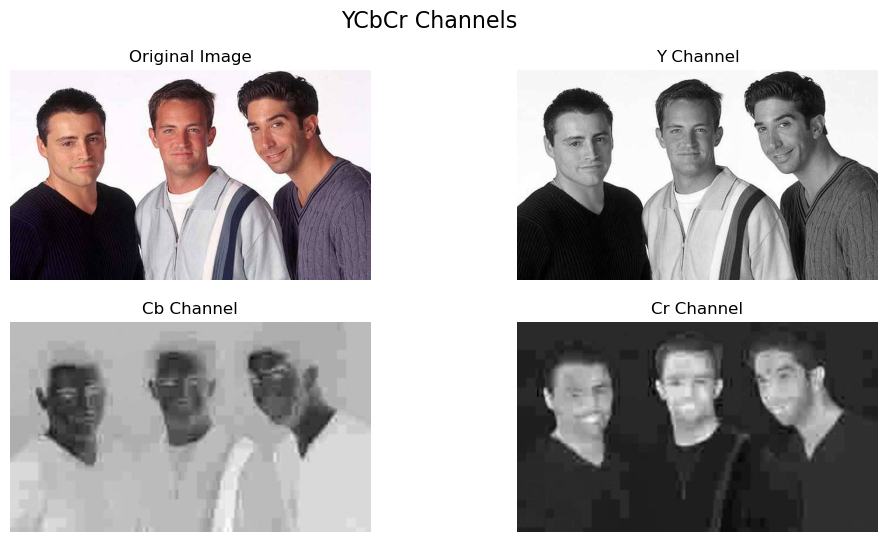

In [5]:
def rgb_to_ycbcr(rgb_img):
    img = rgb_img.astype(float)
    r, g, b = img[:,:,0], img[:,:,1], img[:,:,2]
    
    y  =  0.299   * r + 0.587   * g + 0.114   * b
    cb = -0.16874 * r - 0.33126 * g + 0.5     * b + 128
    cr =  0.5     * r - 0.41869 * g - 0.08131 * b + 128
    
    return y, cb, cr

y, cb, cr = rgb_to_ycbcr(image_rgb)

plt.figure(figsize=(12,6))
plt.suptitle('YCbCr Channels', size=16)

plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(image_rgb)
plt.axis('off')

plt.subplot(2,2,2)
plt.title('Y Channel')
plt.imshow(y, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title('Cb Channel')
plt.imshow(cb, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title('Cr Channel')
plt.imshow(cr, cmap='gray')
plt.axis('off')

## Grayscale

(-0.5, 617.5, 359.5, -0.5)

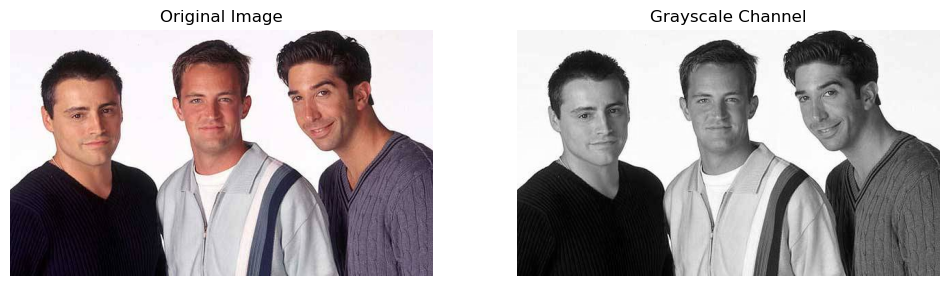

In [6]:
def rgb_to_gray(rgb_img):
    r, g, b = rgb_img[:,:,0], rgb_img[:,:,1], rgb_img[:,:,2]
    
    gray_img = 0.299 * r + 0.587 * g + 0.114 * b
    
    return gray_img.astype(np.uint8)

image_grayscale = rgb_to_gray(image_rgb)

plt.figure(figsize=(12,8))
plt.subplot(1,2,1)
plt.title('Original Image')
plt.imshow(image_rgb)
plt.axis('off')

plt.subplot(1,2,2)
plt.title('Grayscale Channel')
plt.imshow(image_grayscale, cmap='gray')
plt.axis('off')

## Normalized RGB & Face Detection Mask

(-0.5, 617.5, 359.5, -0.5)

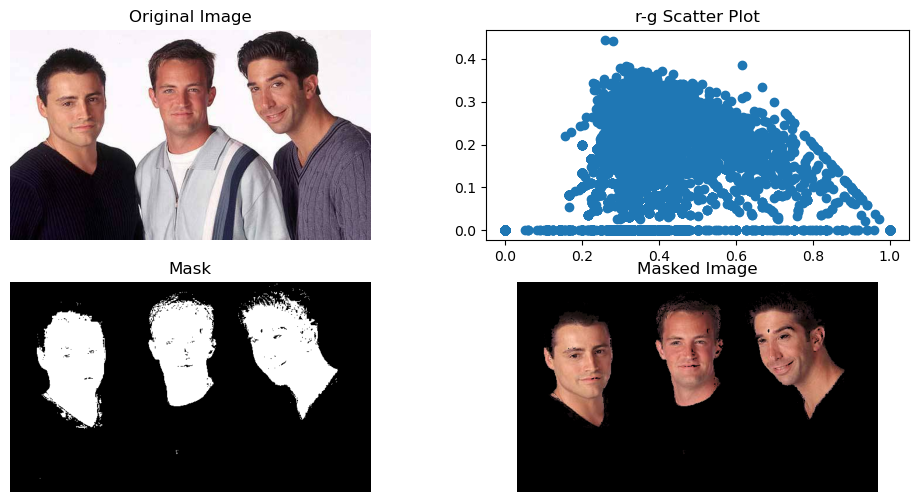

In [7]:
def face_detection_mask(img):
    r, g, b = img[:,:,0], img[:,:,1], img[:,:,2]
    sum_rgb = np.sum(image_rgb, axis=2)
    sum_rgb[sum_rgb == 0] = 1 #Avoid division by zero
    rn = r / sum_rgb
    gn = g / sum_rgb
    
    mask = (rn > 0.4) & (rn < 0.7) & (gn > 0.23) & (gn < 0.44)
    
    result = img * mask[:, :, np.newaxis]
    return result, mask, rn, gn

result, mask, rn, gn = face_detection_mask(image_rgb)

plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
plt.title('Original Image')
plt.imshow(image_rgb)
plt.axis('off')

plt.subplot(2,2,2)
plt.title('r-g Scatter Plot')
plt.scatter(rn, gn)

plt.subplot(2,2,3)
plt.title('Mask')
plt.imshow(mask, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title('Masked Image')
plt.imshow(result)
plt.axis('off')

# Question 2

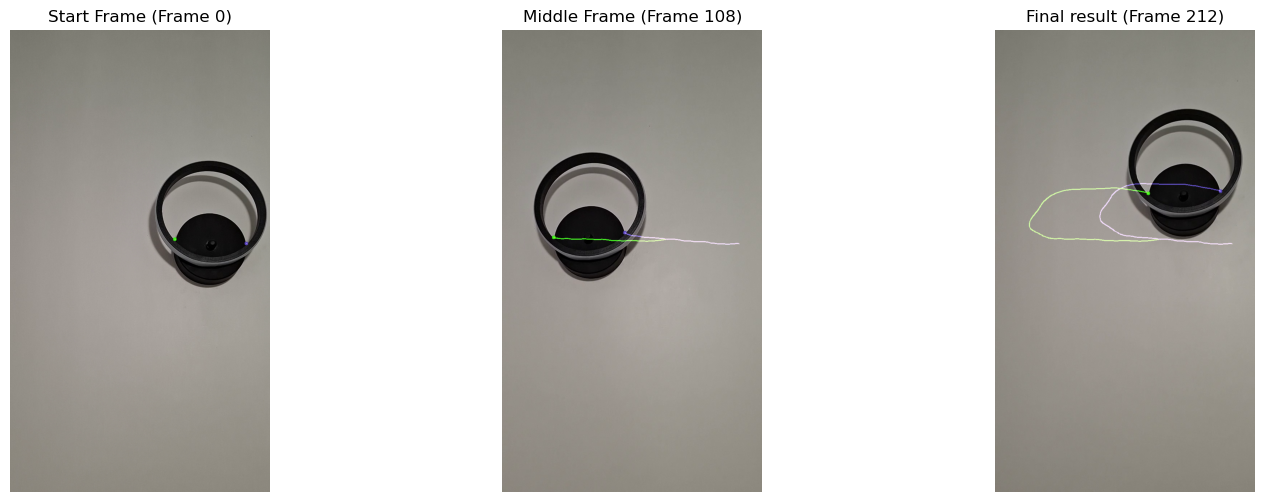

In [8]:
video_path = './img_and_vids/vid1.mp4'
cap = cv2.VideoCapture(video_path)

feature_params = dict(maxCorners=100, qualityLevel=0.3, minDistance=7, blockSize=7)
lk_params = dict(winSize=(15, 15), maxLevel=2, criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
save_at = [0, total_frames // 2, total_frames - 5]
captured_images = []

ret, old_frame = cap.read()
old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)
p0 = cv2.goodFeaturesToTrack(old_gray, mask=None, **feature_params)
mask = np.zeros_like(old_frame)
color = np.random.randint(0, 255, (100, 3))

frame_idx = 0
while cap.isOpened():
    ret, frame = cap.read()
    if not ret: 
        break
    
    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    p1, st, err = cv2.calcOpticalFlowPyrLK(old_gray, frame_gray, p0, None, **lk_params)

    if p1 is not None:
        good_new = p1[st == 1]
        good_old = p0[st == 1]

        for i, (new, old) in enumerate(zip(good_new, good_old)):
            a, b = new.ravel()
            c, d = old.ravel()
            mask = cv2.line(mask, (int(a), int(b)), (int(c), int(d)), color[i].tolist(), 2)
            frame = cv2.circle(frame, (int(a), int(b)), 5, color[i].tolist(), -1)

    output_img = cv2.add(frame, mask)
    
    if frame_idx in save_at:
        captured_images.append(cv2.cvtColor(output_img, cv2.COLOR_BGR2RGB))

    cv2.imshow('Tracking...', output_img)
    if cv2.waitKey(30) & 0xFF == 27: 
        break

    old_gray = frame_gray.copy()
    p0 = good_new.reshape(-1, 1, 2)
    frame_idx += 1

cap.release()
cv2.destroyAllWindows()

plt.figure(figsize=(18, 6))

plt.subplot(1,3,1)
plt.title(f'Start Frame (Frame {save_at[0]})')
plt.imshow(captured_images[0])
plt.axis('off')

plt.subplot(1,3,2)
plt.title(f'Middle Frame (Frame {save_at[1]})')
plt.imshow(captured_images[1])
plt.axis('off')

plt.subplot(1,3,3)
plt.title(f'Final result (Frame {save_at[2]})')
plt.imshow(captured_images[2])
plt.axis('off')
plt.show()

# Question 3

In [ ]:
video_path = './img_and_vids/vid2.mp4'
cap = cv2.VideoCapture(video_path)

feature_params = dict(maxCorners=150, qualityLevel=0.3, minDistance=10, blockSize=7)
lk_params = dict(winSize=(21, 21), maxLevel=3, 
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 20, 0.01))

ret, old_frame = cap.read()

old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)
p0 = cv2.goodFeaturesToTrack(old_gray, mask=None, **feature_params)

mask = np.zeros_like(old_frame)

while cap.isOpened():
    ret, frame = cap.read()
    if not ret: break
    
    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    p1, st, err = cv2.calcOpticalFlowPyrLK(old_gray, frame_gray, p0, None, **lk_params)

    if p1 is not None:
        good_new = p1[st == 1]
        good_old = p0[st == 1]

        M, inliers = cv2.estimateAffinePartial2D(good_old, good_new, method=cv2.RANSAC, ransacReprojThreshold=1.0)
        
        if inliers is not None:
            inliers = inliers.ravel()
            for i, (new, old) in enumerate(zip(good_new, good_old)):
                a, b = new.ravel().astype(int)
                c, d = old.ravel().astype(int)
                
                if inliers[i]:
                    cv2.circle(frame, (a, b), 8, (0, 255, 0), -1) 
                    mask = cv2.line(mask, (a, b), (c, d), (0, 200, 0), 2)
                else:
                    cv2.circle(frame, (a, b), 12, (0, 0, 255), -1)
                    mask = cv2.line(mask, (a, b), (c, d), (0, 0, 255), 3)

        output = cv2.addWeighted(frame, 0.7, mask, 0.3, 0)
        
        cv2.imshow('Green: Background & Red: Moving Objects', output)

    if cv2.waitKey(30) & 0xFF == 27:
        break
    old_gray = frame_gray.copy()
    p0 = good_new.reshape(-1, 1, 2)

#cv2.imwrite('./figs/motion_separation_result.png', output)

cap.release()
cv2.destroyAllWindows()

(-0.5, 719.5, 1279.5, -0.5)

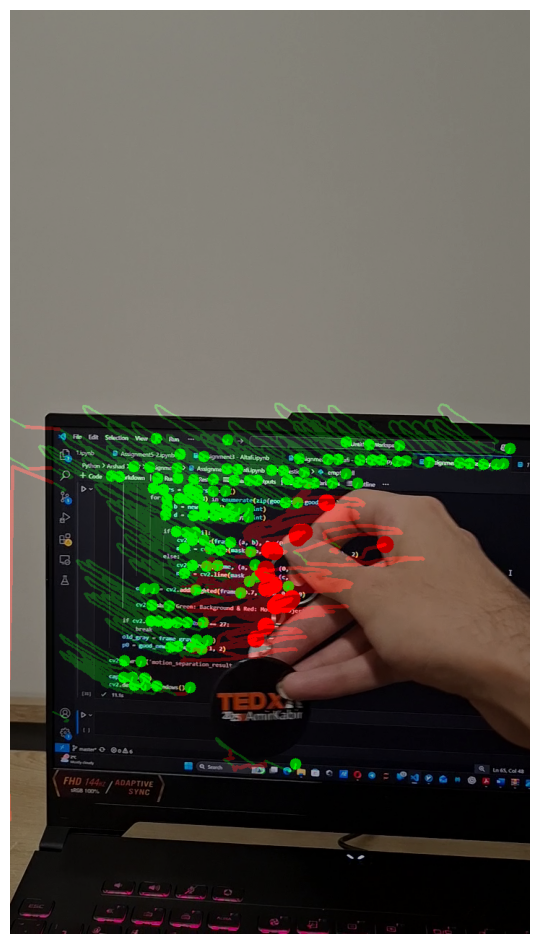

In [10]:
plt.figure(figsize=(24,12))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.axis('off')